In [6]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
from scipy.stats import gaussian_kde
from matplotlib import font_manager as fm

font_path = "computer-modern/cmunbmr.ttf"
fm.fontManager.addfont(font_path)                      # make matplotlib aware of it
font_name = fm.FontProperties(fname=font_path).get_name()

plt.rcParams["font.family"] = font_name  

# Edit these paths to match your files.
CSV_FILES = {
    "baseline": Path("../../results/base_baseline_5000_2026-11-04_19-47-16.csv"),
    "ebpf-dynamic": Path("../../results/proxy_dynamic_srv6-ipv4-10_5000_2026-11-08_09-57-04.csv"),
    "ebpf-lane-based": Path("../../results/proxy_lane-based_srv6-ipv4-10_5000_2026-11-07_22-08-09.csv"),
    "ebpf-field-based": Path("../../results/proxy_fields-based_ipv4-src-dst-10_5000_2026-11-07_22-02-59.csv"),
    "user-space": Path("../../results/proxy_user-space-run-0_5000_2026-11-04_16-43-04.csv"),
}

# Set to 0 if the CSV files have a header row; leave as None if they have no header.
HEADER = 0
EXPECTED_ROWS = 5000
ALPHA = 0.05

In [7]:
datasets = {}

for name, path in CSV_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Could not find {path.resolve()}")

    frame = pd.read_csv(path, header=HEADER)
    if frame.shape[1] != 1:
        raise ValueError(f"{path} must contain exactly one column; found {frame.shape[1]}")
    if len(frame) != EXPECTED_ROWS:
        raise ValueError(f"{path} contains {len(frame)} rows; expected {EXPECTED_ROWS}")

    values = pd.to_numeric(frame.iloc[:, 0], errors="raise").to_numpy(dtype=float) / 1000
    if not np.isfinite(values).all():
        raise ValueError(f"{path} contains NaN or infinite values")

    datasets[name] = values

print("Loaded datasets:")
for name, values in datasets.items():
    print(f"{name}: n={len(values)}")


Loaded datasets:
baseline: n=5000
ebpf-dynamic: n=5000
ebpf-lane-based: n=5000
ebpf-field-based: n=5000
user-space: n=5000


In [8]:

import pandas as pd
import pingouin as pg
import scikit_posthocs as sp
from scipy import stats
import dataframe_image as dfi

# long format: one row per measurement
df = pd.concat(
    [pd.DataFrame({"group": k, "value": v}) for k, v in datasets.items()],
    ignore_index=True,
)

# Pairwise on means: Games-Howell (Welch-style, built-in multiple-comparison correction)
display(pg.pairwise_gameshowell(data=df, dv="value", between="group"))

# Pairwise rank-based: Mann-Whitney with Holm correction and effect size
mann_whitney = pg.pairwise_tests(data=df, dv="value", between="group", parametric=False, padjust="holm", effsize="CLES")
display(mann_whitney)

# Alternative rank-based post-hoc after Kruskal-Wallis: Dunn's test
dunn = sp.posthoc_dunn(df, val_col="value", group_col="group", p_adjust="holm")
display(dunn)

# dfi.export(mann_whitney.style.format(precision=4).hide(axis="index"), f"{name}.png", table_conversion="matplotlib")

,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,baseline,ebpf-dynamic,10.428144,37.000857,-26.572713,0.126212,-210.541134,9423.202935,8.151257e-13,-4.210507
1,baseline,ebpf-field-based,10.428144,41.323820,-30.895676,0.130524,-236.704345,9192.988542,0.000000e+00,-4.733732
2,baseline,ebpf-lane-based,10.428144,40.893131,-30.464987,0.126567,-240.701790,9404.531628,2.887912e-12,-4.813675
3,baseline,user-space,10.428144,301.467302,-291.039158,1.526555,-190.650905,5024.797638,0.000000e+00,-3.812732
4,ebpf-dynamic,ebpf-field-based,37.000857,41.323820,-4.322963,0.144813,-29.852041,9970.204731,0.000000e+00,-0.596996
5,ebpf-dynamic,ebpf-lane-based,37.000857,40.893131,-3.892274,0.141257,-27.554589,9997.796829,0.000000e+00,-0.551050
6,ebpf-dynamic,user-space,37.000857,301.467302,-264.466445,1.527843,-173.097876,5041.719474,0.000000e+00,-3.461698
7,ebpf-field-based,ebpf-lane-based,41.323820,40.893131,0.430689,0.145123,2.967747,9974.726704,2.504977e-02,0.059350
8,ebpf-field-based,user-space,41.323820,301.467302,-260.143482,1.528206,-170.228054,5046.481908,0.000000e+00,-3.404306
9,ebpf-lane-based,user-space,40.893131,301.467302,-260.574171,1.527873,-170.547030,5042.106358,0.000000e+00,-3.410685


,Contrast,A,B,Paired,Parametric,U_val,alternative,p_unc,p_corr,p_adjust,CLES
0,group,baseline,ebpf-dynamic,False,False,390692.5,two-sided,0.000000e+00,0.000000e+00,holm,0.015628
1,group,baseline,ebpf-field-based,False,False,199996.0,two-sided,0.000000e+00,0.000000e+00,holm,0.008000
2,group,baseline,ebpf-lane-based,False,False,206697.5,two-sided,0.000000e+00,0.000000e+00,holm,0.008268
3,group,baseline,user-space,False,False,0.0,two-sided,0.000000e+00,0.000000e+00,holm,0.000000
4,group,ebpf-dynamic,ebpf-field-based,False,False,7552514.5,two-sided,1.586849e-257,4.760547e-257,holm,0.302101
5,group,ebpf-dynamic,ebpf-lane-based,False,False,7802957.5,two-sided,2.519716e-232,5.039432e-232,holm,0.312118
6,group,ebpf-dynamic,user-space,False,False,0.0,two-sided,0.000000e+00,0.000000e+00,holm,0.000000
7,group,ebpf-field-based,ebpf-lane-based,False,False,12849534.0,two-sided,1.544051e-02,1.544051e-02,holm,0.513981
8,group,ebpf-field-based,user-space,False,False,0.0,two-sided,0.000000e+00,0.000000e+00,holm,0.000000
9,group,ebpf-lane-based,user-space,False,False,0.0,two-sided,0.000000e+00,0.000000e+00,holm,0.000000


,baseline,ebpf-dynamic,ebpf-field-based,ebpf-lane-based,user-space
baseline,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0
ebpf-dynamic,0.0,1.000000e+00,3.833878e-97,1.319690e-85,0.0
ebpf-field-based,0.0,3.833878e-97,1.000000e+00,1.851731e-01,0.0
ebpf-lane-based,0.0,1.319690e-85,1.851731e-01,1.000000e+00,0.0
user-space,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.0


In [9]:
summary = pd.DataFrame({
    name: {
        "n": len(values),
        "mean": np.mean(values),
        "std_dev": np.std(values, ddof=1),
        "median": np.median(values),
    }
    for name, values in datasets.items()
}).T

display(summary)


,n,mean,std_dev,median
baseline,5000.0,10.428144,5.476118,9.298
ebpf-dynamic,5000.0,37.000857,7.046903,35.524
ebpf-lane-based,5000.0,40.893131,7.078742,39.100
ebpf-field-based,5000.0,41.323820,7.429343,39.577
user-space,5000.0,301.467302,107.804769,278.949


findfont: Failed to find font weight normal for CMU Bright, now using 500.
findfont: Failed to find font weight normal for CMU Bright, now using 500.


  agg_filter: a filter function, which takes a (m, n, 3) float array and a dpi value, and returns a (m, n, 3) array and two offsets from the bottom left corner of the image
  alpha: float or None
  animated: bool
  antialiased: bool
  backgroundcolor: :mpltype:`color`
  bbox: dict with properties for `.FancyBboxPatch` or None
  clip_box: `~matplotlib.transforms.BboxBase` or None
  clip_on: bool
  clip_path: Patch or (Path, Transform) or None
  color or c: :mpltype:`color`
  figure: `~matplotlib.figure.Figure` or `~matplotlib.figure.SubFigure`
  fontfamily or family or fontname: {FONTNAME, 'serif', 'sans-serif', 'cursive', 'fantasy', 'monospace'}
  fontfeatures: list of str, or tuple of str, or None
  fontproperties or font or font_properties: `.font_manager.FontProperties` or `str` or `pathlib.Path`
  fontsize or size: float or {'xx-small', 'x-small', 'small', 'medium', 'large', 'x-large', 'xx-large'}
  fontstretch or stretch: {a numeric value in range 0-1000, 'ultra-condensed', 'extra

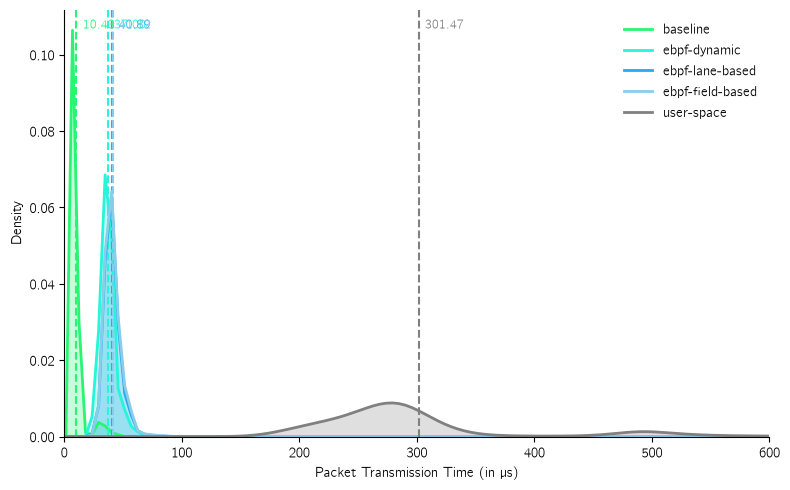

In [10]:
colors = ["#27F573", "#27F5DA", "#27A9F5", "skyblue", "grey"]
# Shared x-range so all curves are drawn on the same axis
all_values = np.concatenate(list(datasets.values()))
pad = 0.1 * np.ptp(all_values)
x = np.linspace(all_values.min() - pad, all_values.max() + pad, 500)
 
fig, ax = plt.subplots(figsize=(8, 5))
 
for (label, values), color in zip(datasets.items(), colors):
    kde = gaussian_kde(values)   # smoothed histogram (Gaussian KDE)
    y = kde(x)
    mean = values.mean()
 
    ax.plot(x, y, color=color, lw=2, label=label)
    ax.fill_between(x, y, color=color, alpha=0.25)          # colored area under the line
    ax.axvline(mean, color=color, ls="--", lw=1.5)           # mean marker
    ax.text(mean + 2, ax.get_ylim()[1] * 0.98, f" {mean:.2f}",
            color=color, rotation=0, va="top", ha="left", fontsize=9)
 
ax.set_xlabel("Packet Transmission Time (in µs)")
ax.set_ylabel("Density")
ax.set_ylim(bottom=0)
ax.set_xlim(0, 600)
plt.setp(ax.get_yticklabels())
plt.setp(ax.get_xticklabels())
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
 
plt.tight_layout()
plt.savefig("rendered/smoothed_hist.png", dpi=150)
plt.show()

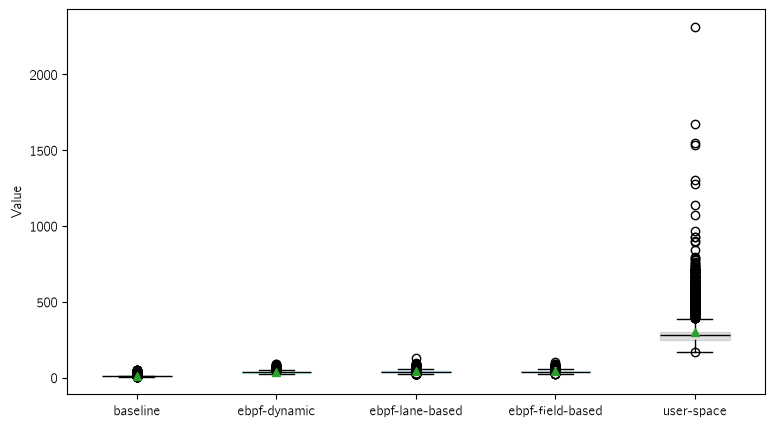

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(
    datasets.values(),               # the three arrays
    positions=[1, 2, 3, 4, 5],         # x position of each box
    widths=0.5,
    patch_artist=True,           # needed to fill the boxes with color
    showmeans=True,              # marks the mean as well
    medianprops=dict(color="black"),
)
# color each box like in the density plot (alpha 0.25 fill)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.25)
    patch.set_edgecolor(color)

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(datasets.keys())
ax.set_ylabel("Value")


#ax.set_ylim(0, 400)

plt.show()

/var/folders/nm/gj6345jx03707dzzvkc2j9r00000gn/T/ipykernel_60476/4029334490.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(names, font=fpath)


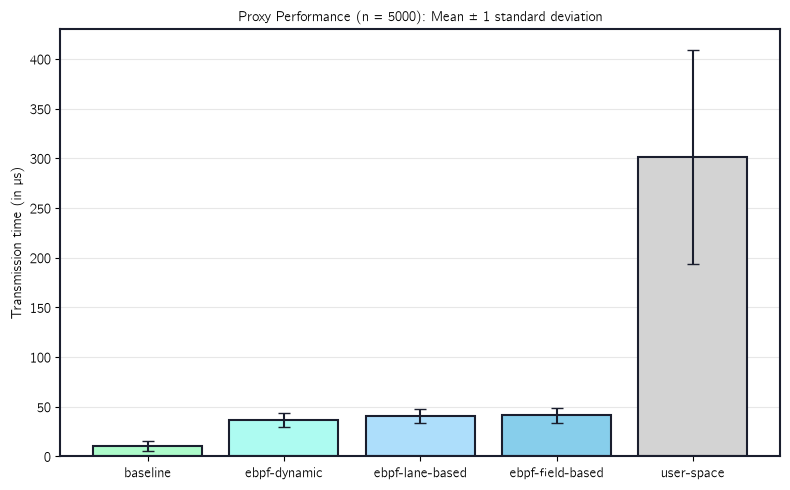

In [12]:
names = list(datasets.keys())
means = [np.mean(datasets[name]) for name in names]
std_devs = [np.std(datasets[name], ddof=1) for name in names]
fpath = Path("computer-modern/cmunbmr.ttf")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    names, 
    means, 
    yerr=std_devs, 
    capsize=4,
    color=["#27F57360", "#27F5DA60", "#27A9F560", "skyblue", "lightgrey"],
    edgecolor=["#1a1e2e"],
    ecolor="#1a1e2e",
    linewidth=1.5,
    )
ax.set_ylabel("Transmission time (in µs)", font=fpath)
ax.set_title("Proxy Performance (n = 5000): Mean ± 1 standard deviation", font=fpath)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.set_xticklabels(names, font=fpath)
plt.setp(ax.get_yticklabels(), font=fpath)
plt.tight_layout()

for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("#1a1e2e")


plt.show()


fig.savefig("rendered/barplots.png", dpi=300, bbox_inches="tight")
